# MinuteMind – Exploratory Data Analysis (EDA)

**What is EDA?** Before using any dataset we look at it carefully: how big is it, what is inside, and are there patterns? This notebook does that for `dataset_cleaned.csv` (411 documents).

The data was already cleaned (see `cleaning_log.md`), so here we only **explore and visualise** it.

## 0. Setup
We load the libraries we need and create a folder where the charts will be saved as PNG files.

In [1]:
import os
import numpy as np                # numbers / maths
import pandas as pd               # tables (DataFrames)
import matplotlib.pyplot as plt   # drawing charts
import seaborn as sns             # nicer-looking charts on top of matplotlib

sns.set_theme(style="whitegrid")  # a clean grid background for all charts
os.makedirs("charts", exist_ok=True)   # folder for the saved PNG files

def save(name):
    # Save the current chart as a PNG, then show it on screen
    plt.tight_layout()
    plt.savefig(f"charts/{name}.png", dpi=150)
    plt.show()

## 1. Dataset overview
First we load the file and look at its shape (rows × columns), the data type of each column, the first few rows, summary statistics and missing values.

In [2]:
df = pd.read_csv("dataset_cleaned.csv")   # read the CSV into a table called df
print("Shape (rows, columns):", df.shape)
print()
print(df.dtypes)                          # data type of every column

Shape (rows, columns): (411, 7)

doc_id                     str
source                     str
topic_label                str
word_count               int64
avg_sentence_length    float64
unique_words             int64
readability_score      float64
dtype: object


In [3]:
df.head()   # first 5 rows

,doc_id,source,topic_label,word_count,avg_sentence_length,unique_words,readability_score
0,D00001,Source_12,Health,1120,26.9,505,49.8
1,D00002,Source_5,Science,1144,17.5,605,50.2
2,D00003,Source_5,Business,1577,15.5,319,33.5
3,D00004,Source_18,Sports,1159,25.7,312,37.3
4,D00005,Source_17,Health,1180,27.8,127,40.0


In [4]:
df.describe().round(2)   # count, mean, min, max etc. for the number columns

,word_count,avg_sentence_length,unique_words,readability_score
count,411.00,411.00,411.00,411.00
mean,1218.40,20.09,400.25,54.66
std,473.51,5.92,210.65,14.83
min,130.00,10.00,52.00,30.00
25%,844.00,14.70,217.00,41.65
50%,1206.00,20.30,389.00,55.00
75%,1631.00,25.25,582.50,67.70
max,2000.00,30.00,799.00,79.90


In [5]:
df.isna().sum()   # number of missing values in each column (0 = none)

doc_id                 0
source                 0
topic_label            0
word_count             0
avg_sentence_length    0
unique_words           0
readability_score      0
dtype: int64

**What we see:** 411 rows and 7 columns. `doc_id`, `source` and `topic_label` are text; the other four are numbers. There are no missing values, so we can go straight to analysis.

Numeric columns: `word_count` (length of the document), `avg_sentence_length` (words per sentence), `unique_words` (distinct words used) and `readability_score` (higher = easier to read).

## 2. Topic distribution
How many documents belong to each topic? A bar chart makes it easy to compare.

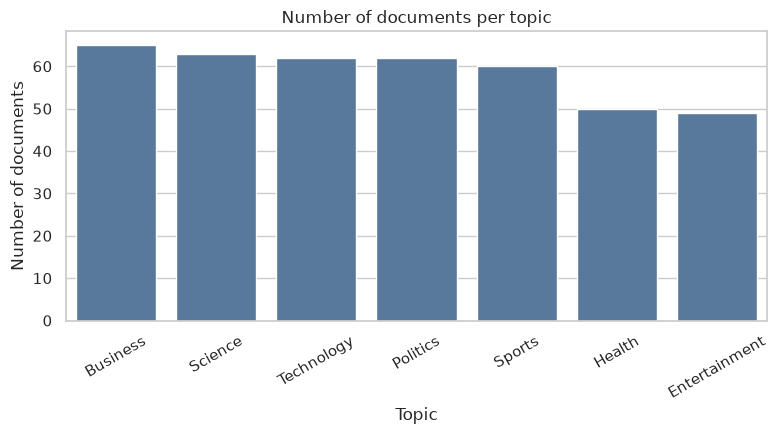

{'Business': 65, 'Science': 63, 'Technology': 62, 'Politics': 62, 'Sports': 60, 'Health': 50, 'Entertainment': 49}


In [6]:
topic_counts = df["topic_label"].value_counts()   # count rows per topic, biggest first

plt.figure(figsize=(8, 4.5))
sns.barplot(x=topic_counts.index, y=topic_counts.values, color="#4C78A8")
plt.title("Number of documents per topic")
plt.xlabel("Topic")
plt.ylabel("Number of documents")
plt.xticks(rotation=30)
save("01_topic_distribution")
print(topic_counts.to_dict())

**Insight:** Topics are fairly balanced (49–65 documents each); Business is the largest and Entertainment the smallest, so no topic dominates.

## 3. Document length (word_count)
A **histogram** groups documents into ranges of length and counts how many fall in each range. A **box plot** shows, for each topic, the middle value (line), the middle 50% of values (box) and the outliers (dots).

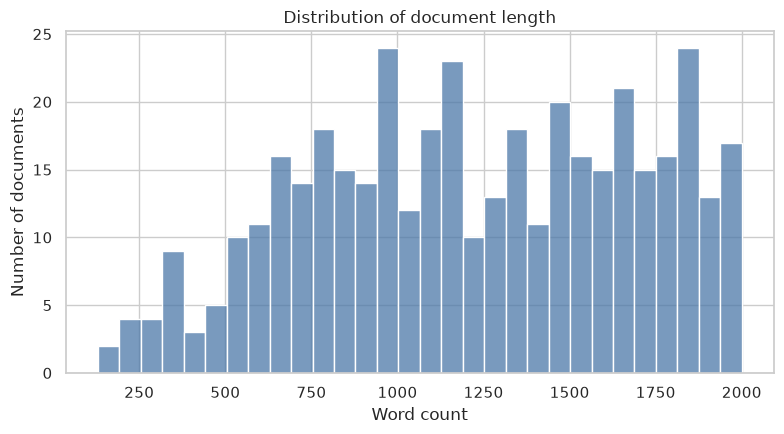

In [7]:
plt.figure(figsize=(8, 4.5))
sns.histplot(df["word_count"], bins=30, color="#4C78A8")
plt.title("Distribution of document length")
plt.xlabel("Word count")
plt.ylabel("Number of documents")
save("02_word_count_hist")

**Insight:** Document lengths are spread almost evenly from about 130 to 2000 words with no clear peak, which is unusual for real-world text.

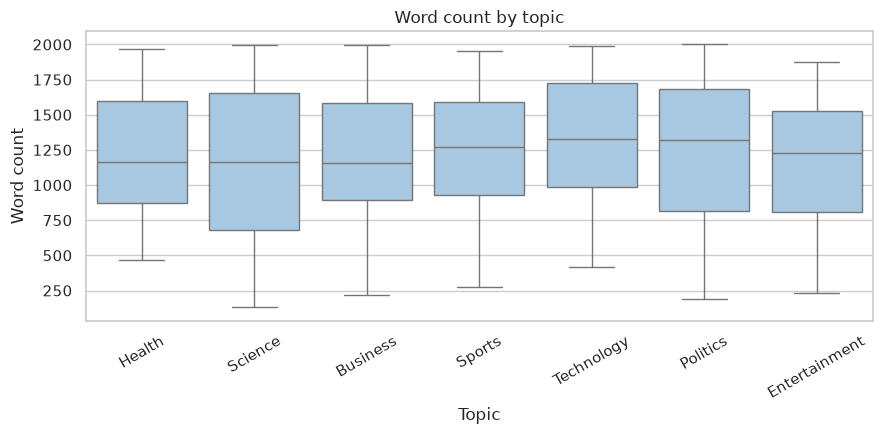

In [8]:
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=df, x="topic_label", y="word_count", color="#9ecae9")
plt.title("Word count by topic")
plt.xlabel("Topic")
plt.ylabel("Word count")
plt.xticks(rotation=30)
save("03_word_count_by_topic")

**Insight:** All topics have similar length ranges (medians roughly 1150–1350 words); Technology and Politics are slightly longer, but the difference is small.

## 4. Readability
`readability_score` tells how easy a document is to read (higher = easier). We look at its overall spread, then compare topics.

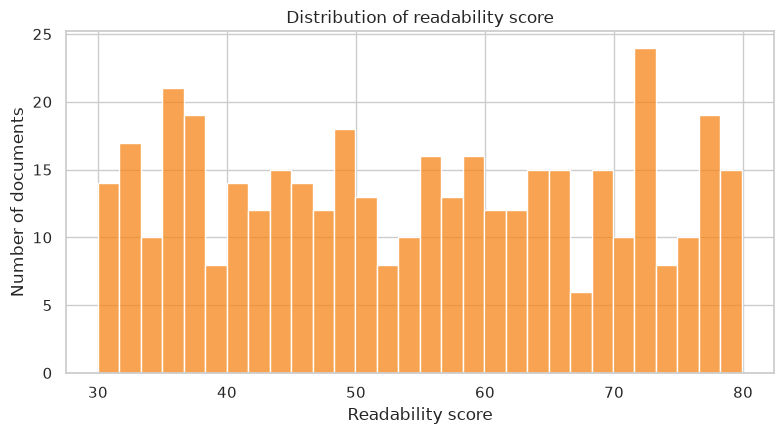

In [9]:
plt.figure(figsize=(8, 4.5))
sns.histplot(df["readability_score"], bins=30, color="#F58518")
plt.title("Distribution of readability score")
plt.xlabel("Readability score")
plt.ylabel("Number of documents")
save("04_readability_hist")

**Insight:** Scores range from 30 to about 80 and are spread fairly flat, again with no bell-shaped peak.

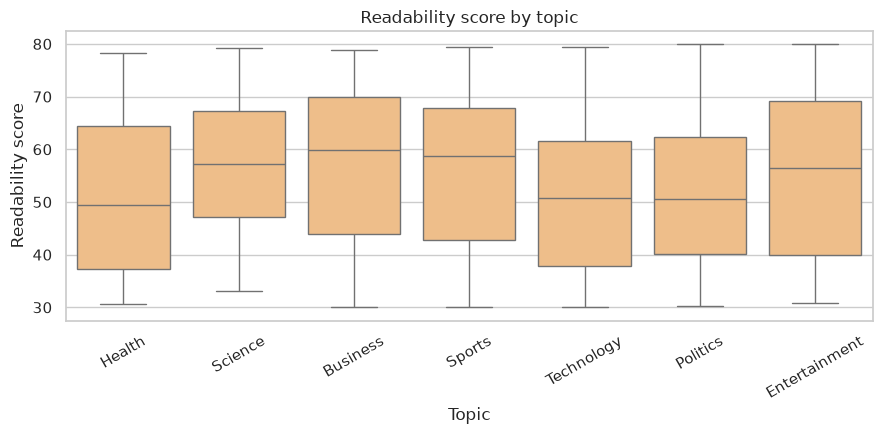

In [10]:
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=df, x="topic_label", y="readability_score", color="#FFBF79")
plt.title("Readability score by topic")
plt.xlabel("Topic")
plt.ylabel("Readability score")
plt.xticks(rotation=30)
save("05_readability_by_topic")

**Insight:** Health, Politics and Technology have lower median readability (about 50) than Business and Sports (about 59), but the boxes overlap a lot, so the difference is weak.

## 5. Correlation heatmap
**Correlation** measures whether two numbers move together. It goes from **-1** (one goes up, the other goes down) through **0** (no relationship) to **+1** (they rise together). The heatmap shows this for every pair of numeric columns; darker/redder = stronger.

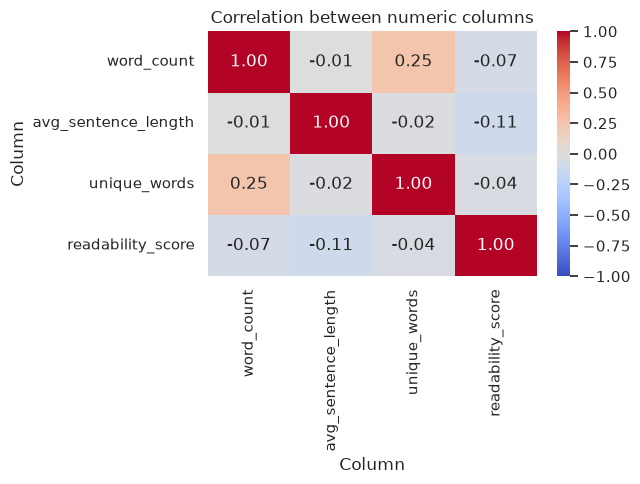

In [11]:
num_cols = ["word_count", "avg_sentence_length", "unique_words", "readability_score"]
corr = df[num_cols].corr()    # correlation between every pair of columns

plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between numeric columns")
plt.xlabel("Column")
plt.ylabel("Column")
save("06_correlation_heatmap")

**Insight:** Almost all pairs are close to 0; the only noticeable link is word_count and unique_words (about 0.25), which makes sense because longer texts contain more distinct words.

## 6. Source analysis
Which of the sources contribute the most documents? We show the top 10.

Total number of different sources: 20


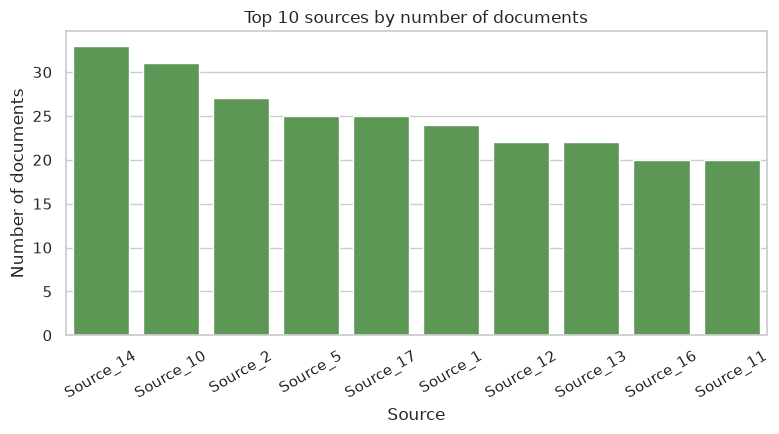

In [12]:
top_sources = df["source"].value_counts().head(10)   # 10 most common sources
print("Total number of different sources:", df["source"].nunique())

plt.figure(figsize=(8, 4.5))
sns.barplot(x=top_sources.index, y=top_sources.values, color="#54A24B")
plt.title("Top 10 sources by number of documents")
plt.xlabel("Source")
plt.ylabel("Number of documents")
plt.xticks(rotation=30)
save("07_top_sources")

**Insight:** There are 20 sources; Source_14 (33 documents) and Source_10 (31) lead, but the counts are fairly even with no single dominant source.

## 7. Relationship: word_count vs unique_words
A **scatter plot** puts one dot per document. Here the x-axis is document length, the y-axis is the number of distinct words, and the colour shows the topic. Since unique words can never exceed total words, every dot must lie below the line y = x.

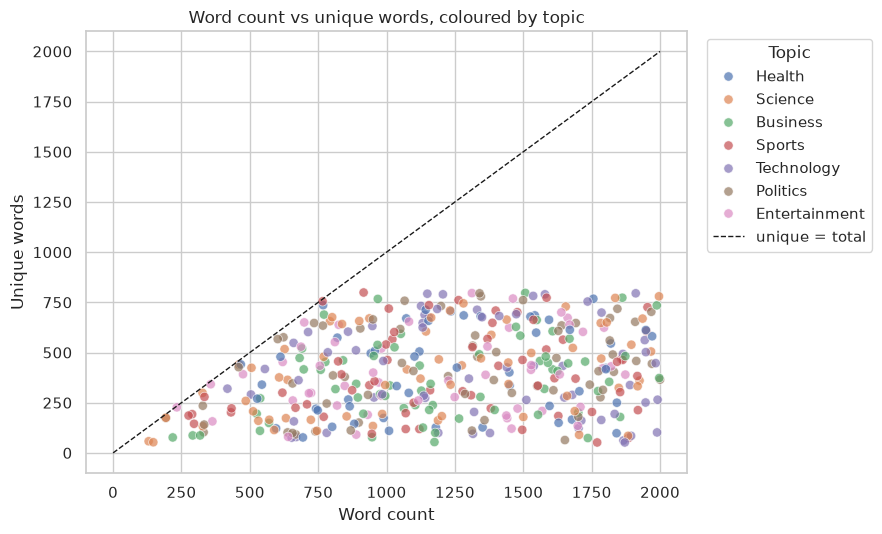

In [13]:
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=df, x="word_count", y="unique_words", hue="topic_label", alpha=0.7, s=45)
# Reference line: unique_words == word_count (the maximum possible)
plt.plot([0, 2000], [0, 2000], "k--", linewidth=1, label="unique = total")
plt.title("Word count vs unique words, coloured by topic")
plt.xlabel("Word count")
plt.ylabel("Unique words")
plt.legend(title="Topic", bbox_to_anchor=(1.02, 1), loc="upper left")
save("08_wordcount_vs_unique")

**Insight:** Dots form a wide cloud with only a weak upward trend and topics are mixed everywhere; unique words ranges from 52 to 799 whatever the length.

## 8. Key findings

1. **411 documents, no missing values**, 7 topics and 20 sources.
2. **Topics are balanced** – each has 49–65 documents.
3. **Length and readability are spread evenly** (130–2000 words; scores 30–80) rather than bell-shaped.
4. **Topics look alike** – medians of length and readability differ only a little between topics.
5. **Columns are almost uncorrelated** – the only visible link is word_count and unique_words (about 0.25).
6. **Sources are evenly used** – the top source has only 33 documents.

### ⚠️ Note: the dataset looks synthetic
Real text data usually shows clear patterns (for example, longer documents having a different readability, or topics with their own style). Here the columns look **independently generated** (random numbers inside fixed ranges): flat distributions, near-zero correlations, and 89 rows originally had more unique words than total words, which is impossible for real text. So conclusions from this data should be treated as a practice exercise, not as real findings about news or meeting text.